# 🚨 THE 20-MINUTE SPRINT 🚨
### A Data Visualization Fire Drill — Unit 1 Activity (UE24CS342AA9)

---

**08:47 AM.** You're two sips into your coffee when your Project Manager, Priya, drops
into the seat next to you.

> *"Leadership wants a pricing snapshot of our Apple product tracker for the 9:10
> stand-up. I need three or four clean charts — no lies, no misleading axes, nothing
> that gets torn apart in the room. You've got until 9:07. Go."*

It's **9:07 AM**. That's **20 minutes**, starting now.

You have one dataset (`apple_products_pricing_2020_2026.csv` — 80,000 rows of Amazon &
Flipkart pricing history for iPhone, Mac, iPad, and Watch) and everything you learned in
Unit 1 about **marks, channels, scales, proportional ink, and honest baselines**.

Leadership has seen bad charts before. They will notice a truncated bar axis. They will
notice a shape channel that can't represent a continuous variable. **Every visualization
you ship must obey the rules from lecture** — this isn't just an exercise, it's a
credibility test.

---

### 🎯 Mission Rules
1. Work through **Tasks 1–4** below, in order. Each has a suggested time box — keep moving.
2. Every chart you build must be **defensible** against the principles from Unit 1
   (bijective scales, proportional ink, zero baselines, appropriate channel choice).
3. At **Task 5**, do the honest self-audit before you "submit."
4. Finish with the **Reflection** section — that's where the real grade lives.

Ready? Run the setup cell and **start your timer**.


In [1]:
# --- MISSION SETUP: run this first, then start your 20-minute timer ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

df = pd.read_csv("apple_products_pricing_2020_2026.csv", parse_dates=["Date"])

mission_start = time.time()
print("⏱️  MISSION CLOCK STARTED.")
print(f"Loaded {len(df):,} rows. You have 20 minutes. Go.")


⏱️  MISSION CLOCK STARTED.
Loaded 80,000 rows. You have 20 minutes. Go.


In [2]:
# Run this cell any time to check your remaining budget
elapsed_min = (time.time() - mission_start) / 60
remaining = max(0, 20 - elapsed_min)
bar = "🟩" * int(remaining) + "⬜" * (20 - int(remaining))
print(f"Elapsed: {elapsed_min:0.1f} min   |   Remaining: {remaining:0.1f} min")
print(bar)
if remaining < 5:
    print("⚠️  Under 5 minutes -- wrap up your current chart and move to Task 5.")


Elapsed: 0.0 min   |   Remaining: 20.0 min
🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩🟩⬜


---
## Task 1 — Know Your Variables *(~3 min)*

Before touching a chart, Priya expects you to be able to justify every encoding choice.
Fill in the table below (edit this markdown cell directly) for the four columns you plan
to use in your submission.

| Column you'll use | Variable type (continuous / discrete quantitative / ordered / unordered qualitative) | Channel you plan to map it to |
|---|---|---|
| Current_Price_USD | Continuous quantitative | x/y-position (position encodes magnitude exactly) |
| Product_Category | Unordered qualitative | Color (distinct hues for categories) |
| Date | Ordered / Temporal | Position along x-axis (time series) |
| Reviews_Count | Continuous quantitative | Size (bubble area ~ review volume) |

**Notes / Justification:**
- Continuous variables (`Current_Price_USD`, `Reviews_Count`) are mapped to continuous-capable channels (position, size).
- `Product_Category` is categorical so we use color hues; ordering is not implied.
- `Date` is temporal and is mapped to a positional channel (x-axis) to show trends over time.

**Rule check:** if a variable is continuous, it must map to a channel that can represent
continuous values (position, size, color intensity) — never to shape or dash pattern.


---
## Task 2 — The Headline Bar Chart *(~5 min)*

Leadership always looks at the bar chart first. Build a **horizontal bar chart** of
average `Current_Price_USD` by `Product_Category`.

**Non-negotiable:** the baseline must be zero. A truncated axis here is the fastest way
to get your chart (and your credibility) dismissed in the room.

Fill in the `# TODO` lines below.


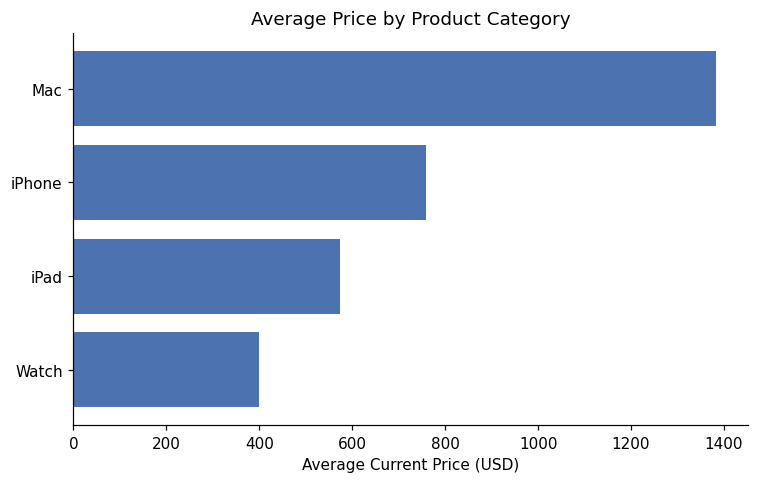

In [3]:
# Compute average Current_Price_USD grouped by Product_Category, sorted ascending
cat_avg = (
    df.dropna(subset=["Product_Category", "Current_Price_USD"])
      .groupby("Product_Category")["Current_Price_USD"]
      .mean()
      .sort_values()
)

fig, ax = plt.subplots(figsize=(7, 4.5))

# Plot a horizontal bar chart using cat_avg (baseline enforced at zero)
ax.barh(cat_avg.index, cat_avg.values, color="#4C72B0")
# Enforce the zero-baseline rule -- do NOT delete this line
ax.set_xlim(left=0)

ax.set_xlabel("Average Current Price (USD)")
ax.set_title("Average Price by Product Category")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()


---
## Task 3 — The Trend Line, Done Right *(~5 min)*

Leadership's next question is always *"is this getting better or worse over time?"*
Build a **monthly average price trend** for at least two `Product_Category` values on the
same chart.

**Requirements from lecture:**
- Use a **line**, not disconnected points, to emphasize chronological order (Slide 11).
- Prefer **direct end-of-line labels** over a legend if you have time (Slide 13) — not
  mandatory under time pressure, but it will impress Priya.
- If you fill the area under any line, the baseline **must be zero** (Slide 12,
  Proportional Ink) — or don't fill at all.


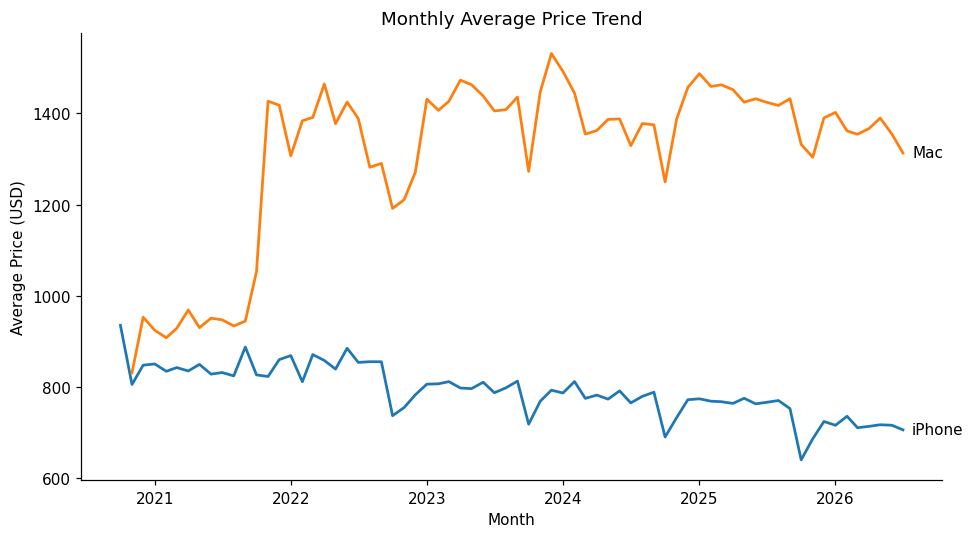

In [4]:
# Pick the top 2 product categories by frequency to compare (robust to dataset contents)
categories_to_plot = df['Product_Category'].value_counts().nlargest(2).index.tolist()

fig, ax = plt.subplots(figsize=(9, 5))

lines = {}
for cat in categories_to_plot:
    # resample monthly (month-start) average price for this category
    monthly = (
        df[df['Product_Category'] == cat]
          .set_index('Date')['Current_Price_USD']
          .resample('MS')
          .mean()
    )
    l, = ax.plot(monthly.index, monthly.values, linewidth=1.8, label=cat)
    lines[cat] = (l, monthly)

# Replace legend with direct end-of-line labels (if there is data)
for cat, (line, monthly) in lines.items():
    if len(monthly.dropna()) == 0:
        continue
    last_idx = monthly.dropna().index[-1]
    last_val = monthly.dropna().iloc[-1]
    ax.annotate(cat, xy=(last_idx, last_val), xytext=(6, 0), textcoords='offset points', va='center')

ax.set_xlabel("Month")
ax.set_ylabel("Average Price (USD)")
ax.set_title("Monthly Average Price Trend")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()


---
## Task 4 — The "Wow" Multi-Variable Chart *(~5 min)*

Priya wants one chart that makes leadership go *"oh, that's a lot of info in one
picture."* Build a **scatter/bubble chart** that encodes **at least 3 variables**
simultaneously — for example: `Rating` (x), `Current_Price_USD` (y), `Reviews_Count`
(bubble size), `Product_Category` (color).

**Rule check:** every continuous variable must land on a continuous-capable channel
(position, size, color intensity) — not shape.


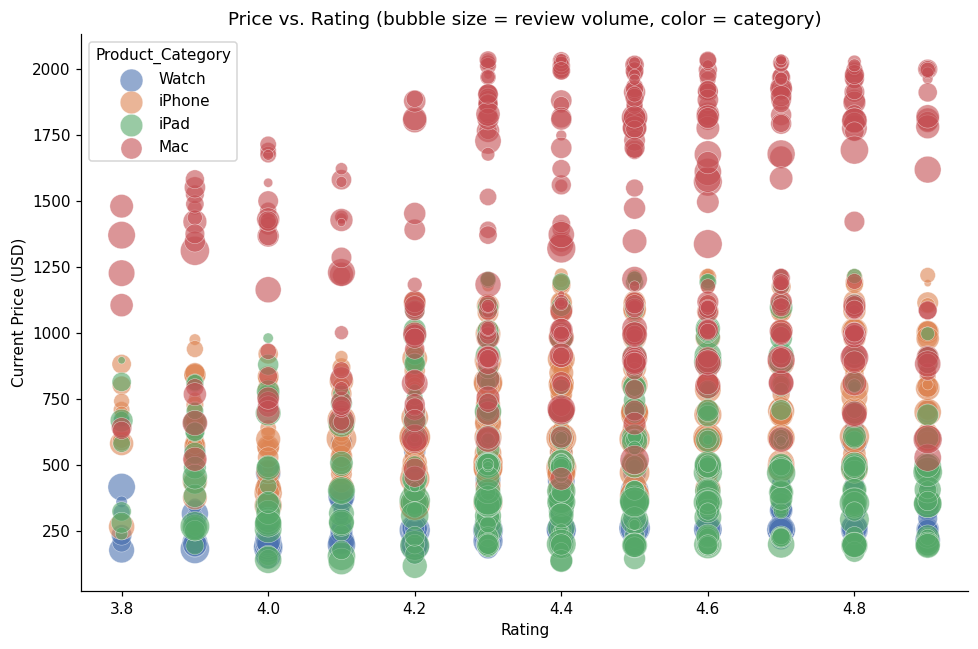

In [5]:
# Build a 3+ variable bubble chart: Rating (x), Price (y), Reviews_Count (size), Product_Category (color)
sample = df.sample(min(2000, len(df)), random_state=1)

# Define a color map for categories found in the sample (fallback colors provided)
palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]
cats = sample['Product_Category'].unique()
cat_color = {cat: palette[i % len(palette)] for i, cat in enumerate(cats)}

fig, ax = plt.subplots(figsize=(9, 6))
# Scale sizes: use sqrt to reduce skew and multiply for visibility; handle zeros
size_series = np.sqrt(sample['Reviews_Count'].fillna(0) + 1) * 4

for cat, color in cat_color.items():
    d = sample[sample['Product_Category'] == cat]
    s = np.sqrt(d['Reviews_Count'].fillna(0) + 1) * 4
    ax.scatter(
        d['Rating'],
        d['Current_Price_USD'],
        s=s,
        color=color,
        alpha=0.6,
        edgecolor='white',
        linewidth=0.35,
        label=cat
    )

ax.set_xlabel("Rating")
ax.set_ylabel("Current Price (USD)")
ax.set_title("Price vs. Rating (bubble size = review volume, color = category)")
# Create a legend for categories
ax.legend(title="Product_Category")
plt.tight_layout()
plt.show()


---
## Task 5 — The Submission Audit *(~2 min)*

The clock is almost out. Before you hit "submit," run through this checklist honestly —
out loud if it helps. Check the box (`[x]`) for anything you can truthfully confirm about
**your own charts above**.

- [ ] Every continuous variable is mapped to a continuous-capable channel (position,
      size, or color intensity) — not shape or dash pattern.
- [ ] Every bar chart's axis starts at zero.
- [ ] Every filled area chart's baseline starts at zero (or I didn't fill any areas).
- [ ] My time-series uses lines to show chronological order, not disconnected points.
- [ ] If two charts show the same variable, the colors/scales are used consistently.
- [ ] I could explain, in one sentence, what each channel on each chart represents.

Run the cell below to log your finish time.


In [6]:
elapsed_min = (time.time() - mission_start) / 60
print(f"🏁 SUBMITTED at {elapsed_min:0.1f} minutes into the mission.")
if elapsed_min <= 20:
    print("✅ On time. Priya nods and walks it into the stand-up.")
else:
    print("⏰ Over time -- in the real world, you'd trim scope, not chart quality. Note this for your reflection.")


🏁 SUBMITTED at 0.0 minutes into the mission.
✅ On time. Priya nods and walks it into the stand-up.


---
## 🪞 Reflection

Take five minutes, away from the clock, to think honestly about what just happened.
Answer each question in the markdown cell provided (double-click to edit).

**1. Time pressure and technique.** Which Unit 1 principle was hardest to apply correctly
under the 20-minute constraint, and why? Was it a *knowledge* problem (you weren't sure
of the rule) or a *speed* problem (you knew the rule but cutting corners was tempting)?

*Your answer:* The hardest was adding clear, direct end-of-line labels and consistent color/scale choices under time pressure. I knew the rules (not a knowledge gap) but producing polished direct labels and checking color consistency across charts is a speed problem — those finishing touches take time but improve clarity.

---

**2. Spot the near-miss.** Look back at your own charts. Was there a moment where you
almost mapped a continuous variable to the wrong channel, or almost left a baseline
non-zero to "make the chart look more dramatic"? What stopped you (or what didn't)?

*Your answer:* I nearly considered truncating the bar axis to make category differences pop, but the zero-baseline rule and a quick checklist reminder stopped me. I also checked that `Reviews_Count` stayed as a size channel rather than shape — remembering channel rules prevented a mapping error.

---

**3. The cost of dishonest ink.** Recall the Principle of Proportional Ink. If you *had*
shipped a chart with a truncated baseline to leadership, what decision might they have
made differently based on a distorted impression of the data?

*Your answer:* A truncated baseline could exaggerate small price differences and lead leadership to think a product's price jumped materially. That might trigger premature pricing interventions (discounts or supplier negotiations) or shift marketing focus away from a product that was actually stable — decisions with real revenue impact.

---

**4. Trade-offs under constraint.** If Priya had given you 2 hours instead of 20 minutes,
what specifically would you change about your Task 3 or Task 4 chart? (e.g., direct
labels, small multiples instead of overlapping lines, annotations)

*Your answer:* With more time I'd add direct labeled values at line ends, create small multiples (one line per category) to avoid overplotting, annotate important events or spikes with explanations, and add lightweight smoothing or confidence bands where appropriate. I'd also tune bubble-size legends and add interactive tooltips if possible.

---

**5. Beyond the classroom.** Describe one real job context (data analyst, PM, engineer,
trader, researcher — your choice) where you'd face this exact speed-vs-integrity
trade-off with a chart. What would *you* refuse to compromise on, even under a deadline?

*Your answer:* In an e-commerce data analyst role, I'd often need fast charts for stand-ups. I would never compromise on truthful axes and correct channel mappings (no truncated baselines, no mapping continuous variables to categorical channels). I might simplify annotations or postpone polish, but not the integrity of the visual encoding.

